In [1]:
import pandas as pd

city_day = pd.read_csv(r"C:\Users\Saud Makandar\Downloads\city_day.csv")

city_day.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [2]:
city_day.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


In [3]:
city_day.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [4]:
city_day.duplicated().sum()

np.int64(0)

In [5]:
city_day.drop_duplicates(inplace=True)

In [6]:
city_day['Date'] = pd.to_datetime(city_day['Date'])

In [7]:
city_day.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [8]:
city_day['PM2.5'].fillna(city_day['PM2.5'].mean(), inplace=True)

C:\Users\Saud Makandar\AppData\Local\Temp\ipykernel_23896\2464648838.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  city_day['PM2.5'].fillna(city_day['PM2.5'].mean(), inplace=True)


0        67.450578
1        67.450578
2        67.450578
3        67.450578
4        67.450578
           ...    
29526    15.020000
29527    24.380000
29528    22.910000
29529    16.640000
29530    15.000000
Name: PM2.5, Length: 29531, dtype: float64

In [9]:
city_day['PM2.5'] = city_day['PM2.5'].fillna(city_day['PM2.5'].mean())

In [10]:
city_day['PM2.5'].isnull().sum()

np.int64(0)

In [11]:
city_day['Date'] = pd.to_datetime(city_day['Date'])

In [12]:
numeric_cols = city_day.select_dtypes(include=['float64']).columns

In [13]:
for col in numeric_cols:
    city_day[col] = city_day[col].fillna(city_day[col].mean())

In [14]:
city_day['AQI_Bucket'] = city_day['AQI_Bucket'].fillna(city_day['AQI_Bucket'].mode()[0])

In [15]:
city_day.describe()

,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,29531,29531.000000,29531.000000,29531.00000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000
mean,2018-05-14 05:40:15.807118,67.450578,118.127103,17.57473,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
min,2015-01-01 00:00:00,0.040000,0.010000,0.02000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,2017-04-16 00:00:00,32.150000,79.315000,6.21000,12.980000,14.670000,12.040000,0.540000,6.090000,20.740000,0.240000,1.280000,2.000000,88.000000
50%,2018-08-05 00:00:00,58.030000,118.127103,11.53000,25.240000,27.550000,23.483476,0.950000,10.480000,34.491430,1.840000,6.930000,3.070128,138.000000
75%,2019-09-03 00:00:00,72.450000,118.127103,17.57473,34.665000,36.015000,23.483476,1.710000,14.531977,42.730000,3.280840,8.700972,3.070128,179.000000
max,2020-07-01 00:00:00,949.990000,1000.000000,390.68000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000
std,NaN,59.414476,71.500953,21.35922,22.941051,29.317936,20.711370,6.715753,16.909088,20.163443,14.226364,17.034769,3.932426,129.064348


In [16]:
city_day['Year'] = city_day['Date'].dt.year

yearly_aqi = city_day.groupby('Year')['AQI'].mean()

yearly_aqi

Year
2015    196.467522
2016    189.165193
2017    176.815421
2018    180.811821
2019    157.019050
2020    116.084655
Name: AQI, dtype: float64

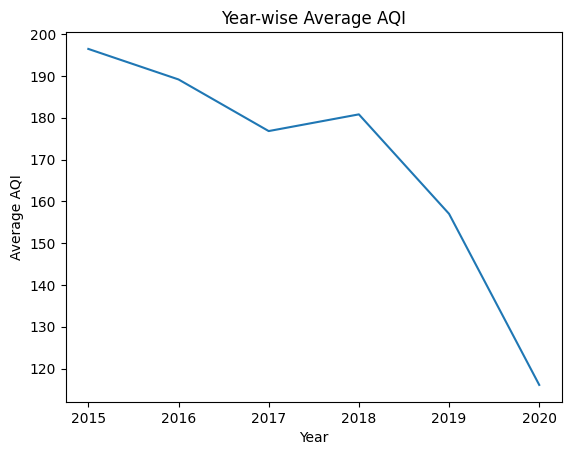

In [17]:
import matplotlib.pyplot as plt

plt.figure()
yearly_aqi.plot()
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.title("Year-wise Average AQI")
plt.show()

In [18]:
city_aqi = city_day.groupby('City')['AQI'].mean().sort_values(ascending=False)

city_aqi.head(10)

City
Ahmedabad       356.144807
Delhi           259.024707
Patna           224.822373
Gurugram        217.227975
Lucknow         214.998893
Talcher         171.310522
Jorapokhar      161.707019
Brajrajnagar    154.162373
Mumbai          142.889029
Kolkata         142.475203
Name: AQI, dtype: float64